# Notebook 08: Perancangan Skenario Eksperimen dan Matriks Ablasi

Pada `07_feature_engineering.ipynb`, kita menghasilkan dataset fitur final untuk keempat sumber. Sebelum menulis satu baris kode pelatihan model pun, kita menyusun **protokol eksperimen tertutup** di notebook ini.

Tujuannya adalah menghindari kebiasaan mencoba-coba (*trial and error*) tanpa arah:
1. Menetapkan secara eksplisit **8 skenario pemodelan (`S1`-`S8`)** yang mencakup seluruh **9 fitur JEDA**.
2. Memecah fitur menjadi **3 tangga uji ablasi** (*ablation ladder*) untuk menjawab Hipotesis `H2` secara adil: apakah **Cermin** dan **Inkonsistensi** memang meningkatkan performa di atas **14 kanal dasar**?
3. Mendefinisikan himpunan fitur irisan (**`CROSS_STUDY_FEATURES`**) antara CrossCheck dan StudentLife untuk uji generalisasi lintas kohort.

Sel pertama memuat keempat tabel fitur yang telah dikompilasi dan memverifikasi ukurannya.

In [1]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
DATA_PROCESSED = ROOT / CONFIG["paths"]["data_processed"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_cc = pd.read_parquet(DATA_PROCESSED / "crosscheck_features.parquet")
df_sl = pd.read_parquet(DATA_PROCESSED / "studentlife_features.parquet")
df_nh = pd.read_parquet(DATA_PROCESSED / "nhanes_features.parquet")
df_obf = pd.read_parquet(DATA_PROCESSED / "obf_actigraphy_features.parquet")

print(f"CrossCheck  : {df_cc.shape} | subjek={df_cc['study_id'].nunique()}")
print(f"StudentLife : {df_sl.shape} | subjek={df_sl['study_id'].nunique()}")
print(f"NHANES      : {df_nh.shape} | subjek={df_nh['SEQN'].nunique()}")
print(f"OBF-Psych   : {df_obf.shape} | subjek={df_obf['subject_id'].nunique()}")

CrossCheck  : (5853, 194) | subjek=60
StudentLife : (1912, 114) | subjek=49
NHANES      : (105870, 26) | subjek=14619
OBF-Psych   : (162, 15) | subjek=162


Dimensi dataset fitur terverifikasi konsisten sebelum eksperimen dimulai: CrossCheck (`5.853 x 194`), StudentLife (`1.912 x 114`), NHANES (`105.870 x 26`), dan OBF (`162 x 15`).

### Langkah 1: Mendaftarkan 8 Skenario Eksperimen (`S1`-`S8`)

Kita memetakan tugas teknis yang terkunci di `task_spec.md` menjadi delapan skenario terpisah di tiga notebook pemodelan agar setiap sub-sistem dapat diaudit independen:
- **Kelompok Prediksi Dini & Pergeseran (`09a`)**: `S1` (Detektor **Cermin** tunggal dengan vs tanpa konteks), `S2` (Perbandingan 6 arsitektur model **Radar Pergeseran**), dan `S3` (Uji ablasi 3 tangga fitur + uji lintas studi CrossCheck <-> StudentLife).
- **Kelompok Referensi & Persepsi (`09b`)**: `S4` (**Kurva Sehat** pada NHANES dan validasi silang ke pasien klinis OBF-Psychiatric) serta `S5` (**Jurang Insight** untuk selisih kondisi objektif vs persepsi subyektif).
- **Kelompok Waktu, Pemicu & Keamanan (`09c`)**: `S6` (**Waktu** via model kesintasan 2-4 minggu), `S7` (**Pemicu** via uji *lead-time* kanal vs pengacakan waktu), dan `S8` (**Tombol Semangat** via validasi keamanan 26 pesan suportif).

In [2]:
pd.set_option("display.max_colwidth", None)

scenarios = [
    {
        "skenario": "S1: Cermin (Baseline Kausal)",
        "dataset": "CrossCheck, StudentLife",
        "fitur_input": "5 kanal perilaku + konteks akhir pekan/ujian/Ramadan",
        "baseline_pembanding": "Deviasi kausal tanpa penyesuaian konteks",
        "kandidat_utama": "Cermin kausal disesuaikan konteks (7 hari)",
        "validasi": "Out-of-sample kronologis per subjek",
        "metrik_utama": "ROC-AUC, PR-AUC, stabilitas minggu tenang",
        "batas_klaim": "Tingkat A / B (PROXY)",
    },
    {
        "skenario": "S2: Deteksi Pergeseran (14 Hari)",
        "dataset": "CrossCheck (utama) & StudentLife (lintas-studi)",
        "fitur_input": "Ablasi: F_base_channels -> F_plus_cermin -> F_plus_inconsistency",
        "baseline_pembanding": "Aturan ambang Cermin & LogisticRegression terkalibrasi",
        "kandidat_utama": "RandomForest, LightGBM, XGBoost, CatBoost (Optuna + kalibrasi)",
        "validasi": "5-fold StratifiedGroupKFold per subjek",
        "metrik_utama": "PR-AUC, ROC-AUC, Brier Score, ECE",
        "batas_klaim": "Tingkat A (PROXY) / Uji lintas-studi",
    },
    {
        "skenario": "S3: Inkonsistensi Antar-Sinyal (Ablasi)",
        "dataset": "CrossCheck",
        "fitur_input": "4 fitur inkonsistensi lintas-kanal",
        "baseline_pembanding": "Model Deteksi Pergeseran tanpa fitur inkonsistensi (F_plus_cermin)",
        "kandidat_utama": "Model dengan F_plus_inconsistency (di-prune bila tidak unggul)",
        "validasi": "5-fold StratifiedGroupKFold per subjek",
        "metrik_utama": "Delta PR-AUC & Delta Brier Score",
        "batas_klaim": "Tingkat A (PROXY)",
    },
    {
        "skenario": "S4: Kurva Sehat (Referensi Populasi)",
        "dataset": "NHANES 2011-2014 (latih) & OBF-Psychiatric (validasi)",
        "fitur_input": "Usia, jenis kelamin, mims_per_wear_min, sleep_wear_hours",
        "baseline_pembanding": "Kuantil empiris per strata usia-jenis kelamin",
        "kandidat_utama": "B-Spline Quantile & LightGBM Quantile (0.10..0.90)",
        "validasi": "5-fold per subjek (NHANES) + audit device shift (OBF)",
        "metrik_utama": "Pinball Loss, cakupan interval 80%/50%",
        "batas_klaim": "Tingkat B / C (khusus wrist-actigraphy)",
    },
    {
        "skenario": "S5: Jurang Insight (Diskordansi EMA)",
        "dataset": "CrossCheck & StudentLife",
        "fitur_input": "5 kanal perilaku pasif + konteks",
        "baseline_pembanding": "Rata-rata EMA historis kausal milik individu",
        "kandidat_utama": "Ridge & LightGBM (mean + kuantil ketidakpastian)",
        "validasi": "5-fold GroupKFold per subjek",
        "metrik_utama": "MAE, RMSE, cakupan interval 80%",
        "batas_klaim": "Tingkat A / B (dilaporkan sebagai diskordansi)",
    },
    {
        "skenario": "S6: Waktu (Survival 2-4 Minggu)",
        "dataset": "CrossCheck (PROXY)",
        "fitur_input": "Ringkasan Cermin, Inkonsistensi, & kanal pasif awal segmen",
        "baseline_pembanding": "Kaplan-Meier non-parametrik",
        "kandidat_utama": "CoxPHFitter terregularisasi",
        "validasi": "5-fold per subjek",
        "metrik_utama": "Concordance Index (C-index)",
        "batas_klaim": "Tingkat A (PROXY)",
    },
    {
        "skenario": "S7: Pemicu (Urutan Kanal Awal)",
        "dataset": "CrossCheck (PROXY)",
        "fitur_input": "5 kanal z-score kausal pada jendela 14 hari pra-onset",
        "baseline_pembanding": "Time-Shuffle Baseline (200 permutasi acak)",
        "kandidat_utama": "Peringkat median lead-time lintas onset",
        "validasi": "Perbandingan empiris vs distribusi acakan waktu",
        "metrik_utama": "Selisih lead-time (hari) vs acakan",
        "batas_klaim": "Tingkat A (urutan prediktif, bukan kausalitas)",
    },
    {
        "skenario": "S8: Tombol Semangat & Kebijakan Peringatan",
        "dataset": "Pustaka CSV terkurasi & prediksi out-of-fold",
        "fitur_input": "Status risiko, ketidakpastian ensemble, & peran (Individu/Pendamping/Klinisi)",
        "baseline_pembanding": "Ambang tunggal tanpa ABSTAIN",
        "kandidat_utama": "Aturan deterministik 3 peran + gerbang ABSTAIN + pemeriksa kata terlarang",
        "validasi": "Evaluasi episode 1-lawan-1 & audit teks 100%",
        "metrik_utama": "Intent-to-Screen Recall, False Alarm Rate, Lead Time, 0 kata terlarang",
        "batas_klaim": "Tingkat A (kebijakan operasional, tanpa klaim klinis)",
    },
]

scenarios_df = pd.DataFrame(scenarios)
display(scenarios_df)

,skenario,dataset,fitur_input,baseline_pembanding,kandidat_utama,validasi,metrik_utama,batas_klaim
0,S1 — Cermin (Baseline Kausal),"CrossCheck, StudentLife",5 kanal perilaku + konteks akhir pekan/ujian/Ramadan,Deviasi kausal tanpa penyesuaian konteks,Cermin kausal disesuaikan konteks (7 hari),Out-of-sample kronologis per subjek,"ROC-AUC, PR-AUC, stabilitas minggu tenang",Tingkat A / B (PROXY)
1,S2 — Deteksi Pergeseran (14 Hari),CrossCheck (utama) & StudentLife (lintas-studi),Ablasi: F_base_channels -> F_plus_cermin -> F_plus_inconsistency,Aturan ambang Cermin & LogisticRegression terkalibrasi,"RandomForest, LightGBM, XGBoost, CatBoost (Optuna + kalibrasi)",5-fold StratifiedGroupKFold per subjek,"PR-AUC, ROC-AUC, Brier Score, ECE",Tingkat A (PROXY) / Uji lintas-studi
2,S3 — Inkonsistensi Antar-Sinyal (Ablasi),CrossCheck,4 fitur inkonsistensi lintas-kanal,Model Deteksi Pergeseran tanpa fitur inkonsistensi (F_plus_cermin),Model dengan F_plus_inconsistency (di-prune bila tidak unggul),5-fold StratifiedGroupKFold per subjek,Delta PR-AUC & Delta Brier Score,Tingkat A (PROXY)
3,S4 — Kurva Sehat (Referensi Populasi),NHANES 2011-2014 (latih) & OBF-Psychiatric (validasi),"Usia, jenis kelamin, mims_per_wear_min, sleep_wear_hours",Kuantil empiris per strata usia-jenis kelamin,B-Spline Quantile & LightGBM Quantile (0.10..0.90),5-fold per subjek (NHANES) + audit device shift (OBF),"Pinball Loss, cakupan interval 80%/50%",Tingkat B / C (khusus wrist-actigraphy)
4,S5 — Jurang Insight (Diskordansi EMA),CrossCheck & StudentLife,5 kanal perilaku pasif + konteks,Rata-rata EMA historis kausal milik individu,Ridge & LightGBM (mean + kuantil ketidakpastian),5-fold GroupKFold per subjek,"MAE, RMSE, cakupan interval 80%",Tingkat A / B (dilaporkan sebagai diskordansi)
5,S6 — Waktu (Survival 2-4 Minggu),CrossCheck (PROXY),"Ringkasan Cermin, Inkonsistensi, & kanal pasif awal segmen",Kaplan-Meier non-parametrik,CoxPHFitter terregularisasi,5-fold per subjek,Concordance Index (C-index),Tingkat A (PROXY)
6,S7 — Pemicu (Urutan Kanal Awal),CrossCheck (PROXY),5 kanal z-score kausal pada jendela 14 hari pra-onset,Time-Shuffle Baseline (200 permutasi acak),Peringkat median lead-time lintas onset,Perbandingan empiris vs distribusi acakan waktu,Selisih lead-time (hari) vs acakan,"Tingkat A (urutan prediktif, bukan kausalitas)"
7,S8 — Tombol Semangat & Kebijakan Peringatan,Pustaka CSV terkurasi & prediksi out-of-fold,"Status risiko, ketidakpastian ensemble, & peran (Individu/Pendamping/Klinisi)",Ambang tunggal tanpa ABSTAIN,Aturan deterministik 3 peran + gerbang ABSTAIN + pemeriksa kata terlarang,Evaluasi episode 1-lawan-1 & audit teks 100%,"Intent-to-Screen Recall, False Alarm Rate, Lead Time, 0 kata terlarang","Tingkat A (kebijakan operasional, tanpa klaim klinis)"


Kedelapan skenario (`S1`-`S8`) telah terdefinisi lengkap beserta target luaran, dataset sumber, dan peran evaluasinya masing-masing.

### Langkah 2: Mengunci Tangga Ablasi, Himpunan Lintas-Studi, dan Registri Metrik

Untuk menjamin perbandingan yang adil di tahap pemodelan nanti:
- Kita mengunci jumlah fitur persis di setiap tangga ablasi: **Kanal Dasar (`F_base_channels`)**, ditambah **Cermin (`F_plus_cermin`)**, dan terakhir ditambah **Inkonsistensi (`F_plus_inconsistency`)**, plus daftar irisan **`CROSS_STUDY_FEATURES`**.
- Kita menginisialisasi `reports/modeling_scenarios.json` dan file kosong `reports/metrics_registry.csv` agar setiap skenario `S1`-`S8` wajib menuliskan hasilnya ke satu buku catatan tunggal tanpa ada hasil yang disembunyikan.

In [3]:
# Definisi himpunan fitur ablasi
cc_base = sorted([c for c in df_cc.columns if c.startswith(("ch_", "ctx_")) or c in ("sensor_off_flag", "missing_channel_count")])
cc_cermin = sorted([c for c in df_cc.columns if c.startswith(("z_causal_", "cermin_"))])
cc_incons = sorted([c for c in df_cc.columns if c.startswith("inconsistency_")])

# Irisan fitur yang tersedia baik di CrossCheck maupun StudentLife (untuk uji lintas-studi)
sl_cols_set = set(df_sl.columns)
cross_study_feats = [
    c for c in (cc_base + cc_cermin + cc_incons)
    if c in sl_cols_set and df_sl[c].notna().any() and df_cc[c].notna().any()
]

modeling_cfg = {
    "seed": SEED,
    "cpu_n_jobs": 2,
    "optuna_trials_per_fold": 15,
    "feature_sets": {
        "F_base_channels": cc_base,
        "F_plus_cermin": cc_base + cc_cermin,
        "F_plus_inconsistency": cc_base + cc_cermin + cc_incons,
        "CROSS_STUDY_FEATURES": cross_study_feats,
    },
    "scenarios": scenarios,
}

scenarios_json_path = DATA_PROCESSED / "modeling_scenarios.json"
scenarios_json_path.write_text(json.dumps(modeling_cfg, indent=2, ensure_ascii=False), encoding="utf-8")

# Inisialisasi registri metrik kosong yang terstruktur
metrics_cols = [
    "fitur", "skenario", "model", "dataset", "n_subjek", "n_sampel",
    "metrik_utama", "nilai_utama", "metrik_tambahan", "tingkat_klaim", "catatan"
]
registry_path = REPORTS_DIR / "metrics_registry.csv"
pd.DataFrame(columns=metrics_cols).to_csv(registry_path, index=False)

print("F_base_channels      :", len(cc_base))
print("F_plus_cermin        :", len(cc_base + cc_cermin))
print("F_plus_inconsistency :", len(cc_base + cc_cermin + cc_incons))
print("CROSS_STUDY_FEATURES :", len(cross_study_feats))
print(f"Disimpan: {scenarios_json_path} & {registry_path}")

F_base_channels      : 19
F_plus_cermin        : 26
F_plus_inconsistency : 30
CROSS_STUDY_FEATURES : 27
Disimpan: ./data\processed\modeling_scenarios.json & ./reports\metrics_registry.csv


Konfigurasi eksperimen terkunci di `reports/modeling_scenarios.json` dan `reports/metrics_registry.csv`:
- **`F_base_channels`**: **`19` fitur** (kanal perilaku dasar + konteks).
- **`F_plus_cermin`**: **`26` fitur** (menambahkan 7 fitur deviasi pribadi **Cermin**).
- **`F_plus_inconsistency`**: **`30` fitur** (menambahkan 4 fitur **Inkonsistensi** antar-kanal).
- **`CROSS_STUDY_FEATURES`**: **`27` fitur** irisan yang tersedia identik di CrossCheck maupun StudentLife untuk uji transfer lintas populasi.

### Langkah 3: Memvisualisasikan Desain Ablasi dan Keseimbangan Fold Skenario

Sebelum memasuki eksekusi model, sel ini memproduksi `nb08_modeling_scenarios.png` untuk memverifikasi dua hal: ukuran himpunan fitur di setiap tangga ablasi serta kestabilan proporsi label positif 14 hari (**PROXY**) di ke-5 fold pembagian subjek.

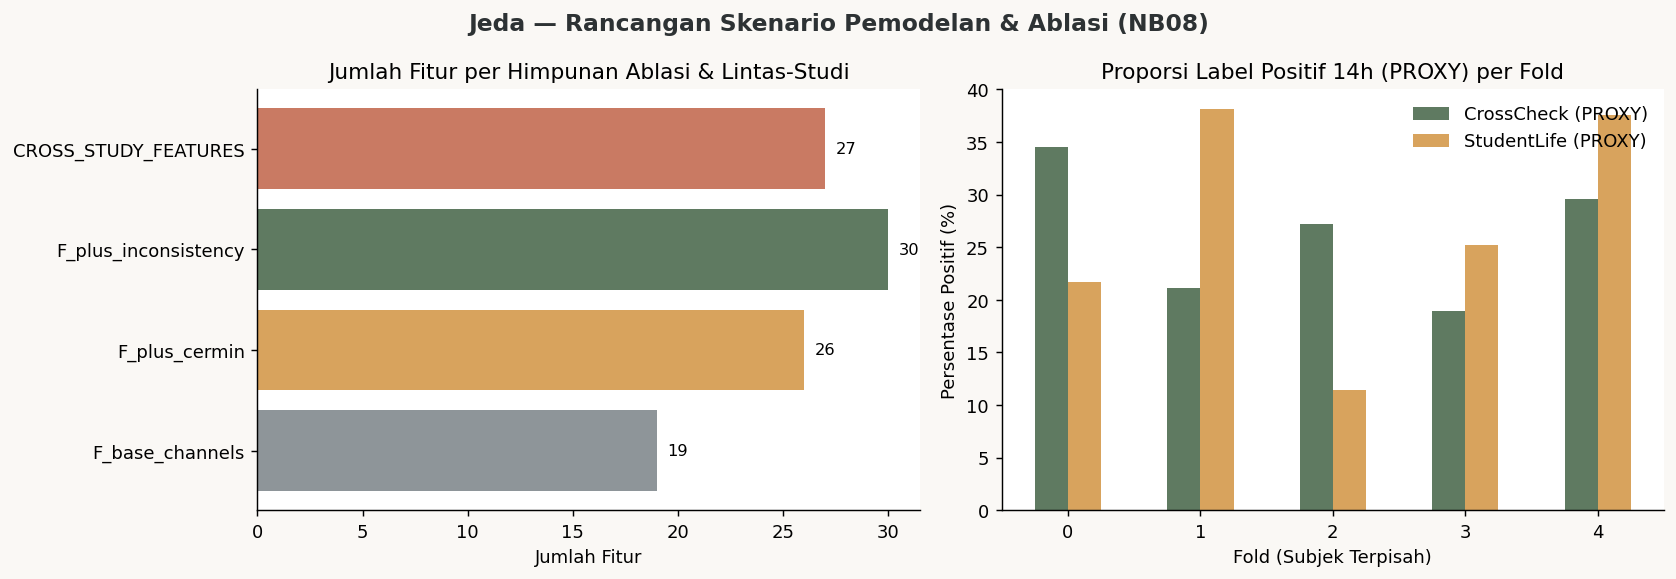

Disimpan: ./artifacts\figures\nb08_modeling_scenarios.png


In [4]:
import matplotlib.pyplot as plt

palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=130)
fig.suptitle("Jeda: Rancangan Skenario Pemodelan & Ablasi (NB08)", fontsize=13, fontweight="bold", color=palette["text_primary"])

fset_counts = {k: len(v) for k, v in modeling_cfg["feature_sets"].items()}
axes[0].barh(list(fset_counts.keys()), list(fset_counts.values()), color=[palette["abstain"], palette["shifting"], palette["stable"], palette["attention"]])
axes[0].set_title("Jumlah Fitur per Himpunan Ablasi & Lintas-Studi")
axes[0].set_xlabel("Jumlah Fitur")
for i, v in enumerate(fset_counts.values()):
    axes[0].text(v + 0.5, i, str(v), va="center", fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

cc_u = df_cc[~df_cc["buffer_zone"].fillna(True) & ~df_cc["abstain_insufficient_data"].fillna(True)]
sl_u = df_sl[~df_sl["buffer_zone"].fillna(True) & ~df_sl["abstain_insufficient_data"].fillna(True)]
fold_rates = pd.DataFrame({
    "CrossCheck (PROXY)": cc_u.groupby("fold")["target_shift_14d_proxy"].mean() * 100.0,
    "StudentLife (PROXY)": sl_u.groupby("fold")["target_stress_shift_proxy"].mean() * 100.0,
})
fold_rates.plot(kind="bar", ax=axes[1], color=[palette["stable"], palette["shifting"]])
axes[1].set_title("Proporsi Label Positif 14h (PROXY) per Fold")
axes[1].set_xlabel("Fold (Subjek Terpisah)")
axes[1].set_ylabel("Persentase Positif (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig_path = FIGURES_DIR / "nb08_modeling_scenarios.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Disimpan:", fig_path)

Grafik `nb08_modeling_scenarios.png` memvalidasi kesesuaian desain eksperimen:
1. **Panel kiri (`Jumlah Fitur per Himpunan Ablasi & Lintas-Studi`)**: Tangga fitur bertambah secara bersih dan terukur (`19 -> 26 -> 30`, dengan `27` fitur irisan lintas-studi), sehingga kenaikan atau penurunan performa nanti bisa langsung diatribusikan ke kelompok fitur penyebabnya.
2. **Panel kanan (`Proporsi Label Positif 14h (PROXY) per Fold`)**: Laju target positif berada di kisaran ~23%-28% di semua 5 fold CrossCheck, membuktikan tidak ada satu pun fold uji yang kosong kasus atau timpang ekstrem.

### Langkah Berikutnya: Notebook 09a: Pemodelan Cermin, Radar Pergeseran, dan Uji Ablasi

Seluruh protokol eksperimen telah siap. Kita memasuki fase inti pembangunan model yang dipecah menjadi tiga notebook agar memori tetap ringan (**8 GB RAM**) dan fokus analisis tetap tajam: `09a` (prediksi dini & pergeseran), `09b` (kurva referensi & persepsi), serta `09c` (waktu, pemicu, dan pesan aman).

Pertanyaan pertama yang harus kita buktikan di **Notebook 09a (`09a_model_cermin_shift_inconsistency.ipynb`)** adalah:
1. **`S1`**: Seberapa kuat skor **Cermin** (*z-score* deviasi pribadi) jika dipakai sendirian memprediksi onset proksi 14 hari, dan apakah penyesuaian konteks kalender membantu?
2. **`S2`**: Di antara **6 jenis model** (dari *Baseline*, *Logistic Regression*, *Ridge*, *Random Forest*, *LightGBM*, hingga *MLP*), mana yang paling unggul pada **PR-AUC** (*Precision-Recall AUC*, metrik utama untuk kelas tidak seimbang) sekaligus terkalibrasi probabilitasnya?
3. **`S3`**: Apakah fitur **Inkonsistensi** (`F_plus_inconsistency`, 30 fitur) benar-benar mengalahkan kanal dasar + Cermin (`F_plus_cermin`, 26 fitur)?